# 09_Finetune_results

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import (precision_score,
                             recall_score,
                             balanced_accuracy_score,
                             f1_score,
                             mean_absolute_error,
                             r2_score,
                             roc_curve,
                             roc_auc_score,
                             precision_recall_curve,
                             average_precision_score)

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
palette = sns.color_palette('Set1')
palette

[(0.8941176470588236, 0.10196078431372549, 0.10980392156862745),
 (0.21568627450980393, 0.49411764705882355, 0.7215686274509804),
 (0.30196078431372547, 0.6862745098039216, 0.2901960784313726),
 (0.596078431372549, 0.3058823529411765, 0.6392156862745098),
 (1.0, 0.4980392156862745, 0.0),
 (1.0, 1.0, 0.2),
 (0.6509803921568628, 0.33725490196078434, 0.1568627450980392),
 (0.9686274509803922, 0.5058823529411764, 0.7490196078431373),
 (0.6, 0.6, 0.6)]

### Loss distribution

In [3]:
epoch_losses = pd.read_excel('../predictions/Finetune_affinity_module/epoch_losses.xlsx')

In [4]:
losses_distr = []
for (epoch, stage), sub_df in epoch_losses.groupby(by=['epoch', 'stage']):
    b_loss = sub_df['b_loss'].sum() / sub_df['step'].max()
    stage_losses = {'stage': stage, 'epoch': epoch, 'b_loss': b_loss}
    losses_distr.append(stage_losses)
losses_distr = pd.DataFrame(losses_distr)

In [5]:
validation_losses_distr = losses_distr[losses_distr['stage'] == 'validation'].reset_index(drop=True)
# Determine the best epoch based on loss
best_epoch = validation_losses_distr.sort_values(by='b_loss', ascending=True).iloc[0]['epoch']
print(f'Best validation loss epoch: {best_epoch}')

Best validation loss epoch: 10


<Axes: xlabel='Epoch', ylabel='BCE loss'>

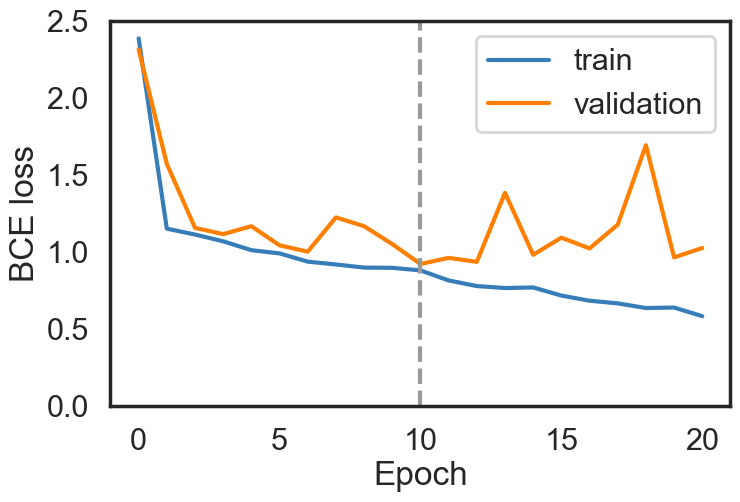

In [7]:
sns.set(rc={'figure.figsize':(8, 5)}, style='white', context='poster')
custom_palette = {'train': palette[1], 'validation': palette[4]}
chart = sns.lineplot(losses_distr, x='epoch', y='b_loss', hue='stage', hue_order=['train', 'validation'], palette=custom_palette)
chart.set(xlabel='Epoch', ylabel='BCE loss', ylim=(0, 2.5))
chart.axvline(x=best_epoch, color=palette[8], linestyle='--')
plt.legend(title='', loc='upper right')
chart.figure.savefig('../figures/supplementary/Supplementary Figure 6 Finetune affinity module learning curves.png', dpi=300, bbox_inches='tight')
chart

### Load model predictions

In [8]:
epoch_predictions = pd.read_excel('../predictions/Finetune_affinity_module/epoch_predictions.xlsx')
epoch_predictions[['cid', 'rid']] = epoch_predictions['record_id'].str.split('-', expand=True).astype('int')

### Find optimal threshold

In [9]:
from sklearn.metrics import precision_recall_curve

def find_best_threshold_pr(logits, y_true):
    probs = 1 / (1 + np.exp(-logits))

    precision, recall, thresholds = precision_recall_curve(y_true, probs)

    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]

    return best_threshold, best_f1

best_model_predictions = epoch_predictions[epoch_predictions['epoch'] == best_epoch].reset_index(drop=True)
best_model_validation_predictions = best_model_predictions[best_model_predictions['stage'] == 'validation'].reset_index(drop=True)
logits = best_model_validation_predictions['affinity_logits_binary2'].to_numpy()
y_true = best_model_validation_predictions['affinity_binary_label'].to_numpy()

In [10]:
best_t, best_f1 = find_best_threshold_pr(logits, y_true)
print(f"Best threshold: {best_t:.3f}, F1: {best_f1:.4f}")

Best threshold: 0.603, F1: 0.5721


### Initial distributions P и N

In [11]:
original_model_predictions = epoch_predictions[epoch_predictions['epoch'] == 0].reset_index(drop=True)
for stage, sub_df in original_model_predictions.groupby(by='stage'):
    label_counts = sub_df['affinity_binary_label'].value_counts().rename({0: 'N', 1: 'P'})
    print(f"{stage}: P = {label_counts['P']}; N = {label_counts['N']}")

test: P = 190; N = 670
train: P = 1137; N = 5107
validation: P = 187; N = 672


### Random model

The model simply predicts the class based on the proportions in the dataset

In [15]:
label_counts = original_model_predictions[original_model_predictions['stage'] == 'train']['affinity_binary_label'].value_counts().rename({0: 'N', 1: 'P'})
P = label_counts['P'] / len(original_model_predictions)
N = label_counts['N'] / len(original_model_predictions)
TP = P * P
FN = P * N
FP = N * P
TN = N * N

precision_value = TP / (TP + FP)
recall_value = TP / (TP + FN)
balanced_accuracy_value =  ((TP / P) + (TN / N)) / 2
f1_score_value = 2 * (precision_value * recall_value) / (precision_value + recall_value)
random_model_metrics = {'precision': precision_value.round(2), 'recall': recall_value.round(2), 'f1-score': f1_score_value.round(2), 'balanced_accuracy': balanced_accuracy_value.round(2)}
random_model_metrics

{'precision': np.float64(0.18),
 'recall': np.float64(0.18),
 'f1-score': np.float64(0.18),
 'balanced_accuracy': np.float64(0.39)}

### Metrcis distribution

In [16]:
def sigmoid(logits):
    probs = 1 / (1 + np.exp(-logits))
    return probs

def calculate_classification_metrics(Y_true, Y_pred, classification_threshold=0.5):

    roc_auc = roc_auc_score(Y_true, Y_pred)
    average_precision = average_precision_score(Y_true, Y_pred)

    Y_pred = (Y_pred >= classification_threshold).astype(float)

    out = {
        'precision': precision_score(Y_true, Y_pred),
        'recall': recall_score(Y_true, Y_pred),
        'balanced_accuracy': balanced_accuracy_score(Y_true, Y_pred),
        'f1-score': f1_score(Y_true, Y_pred),
        'roc_auc': roc_auc,
        'average_precision': average_precision
    }
    return pd.Series(out).round(2)


def calculate_metrics(inp_df, classification_threshold=0.5):

    df = inp_df.copy()
    Y_true_label = df['affinity_binary_label'].to_numpy(dtype=float)
    Y_pred_label = df['affinity_probability_binary2'].to_numpy(dtype=float)
    classification_metrics = calculate_classification_metrics(Y_true_label, Y_pred_label, classification_threshold)
    return classification_metrics

In [17]:
metrics_distr = []
for (stage, epoch), sub_df in epoch_predictions.groupby(by=['stage', 'epoch']):
    meta = pd.Series({'stage': stage, 'epoch': epoch})
    if not epoch == best_epoch:
        metrics = calculate_metrics(sub_df)
    else:
        metrics = calculate_metrics(sub_df, classification_threshold=best_t)
    metrics = pd.concat([metrics, meta])
    metrics_distr.append(metrics.to_frame().T)
metrics_distr = pd.concat(metrics_distr)

In [18]:
metrics_distr[metrics_distr['epoch'] == best_epoch]

,precision,recall,balanced_accuracy,f1-score,roc_auc,average_precision,stage,epoch
0,0.48,0.58,0.7,0.52,0.79,0.6,test,10
0,0.46,0.59,0.72,0.52,0.81,0.53,train,10
0,0.51,0.65,0.74,0.57,0.81,0.57,validation,10


In [19]:
test_predictions = epoch_predictions[(epoch_predictions['epoch'].isin([0, best_epoch]) & (epoch_predictions['stage'] == 'test'))].reset_index(drop=True)
test_predictions['model'] = test_predictions['epoch'].map({0: 'original', best_epoch: 'fine-tuned'})
test_predictions

,record_id,stage,epoch,affinity_probability_binary2,affinity_logits_binary2,affinity_binary_label,cid,rid,model
0,42-2144,test,0,0.778186,1.255127,0,42,2144,original
1,971-44,test,0,0.998289,6.368994,1,971,44,original
2,3153-47,test,0,0.966909,3.374838,0,3153,47,original
3,3381-14,test,0,0.937405,2.706421,0,3381,14,original
4,49-2121,test,0,0.768431,1.199473,0,49,2121,original
...,...,...,...,...,...,...,...,...,...
1715,45-2114,test,10,0.794581,1.352766,0,45,2114,fine-tuned
1716,55-2139,test,10,0.725534,0.972080,0,55,2139,fine-tuned
1717,5063-14,test,10,0.380506,-0.487402,0,5063,14,fine-tuned
1718,60-16,test,10,0.677151,0.740708,0,60,16,fine-tuned


### roc curve

In [20]:
roc_distr = []
for model, sub_df in test_predictions.groupby(by='model'):
    Y_true = sub_df['affinity_binary_label'].to_numpy()
    Y_pred = sub_df['affinity_probability_binary2'].to_numpy()
    fpr, tpr, _ = roc_curve(Y_true, Y_pred)
    score = roc_auc_score(Y_true, Y_pred)
    model_roc = {'model': model, 'fpr': fpr, 'tpr': tpr, 'roc_auc_score': round(score, 2)}
    roc_distr.append(pd.DataFrame(model_roc))
roc_distr = pd.concat(roc_distr, ignore_index=True)

<Axes: xlabel='False Positive Rate', ylabel='True Positive Rate'>

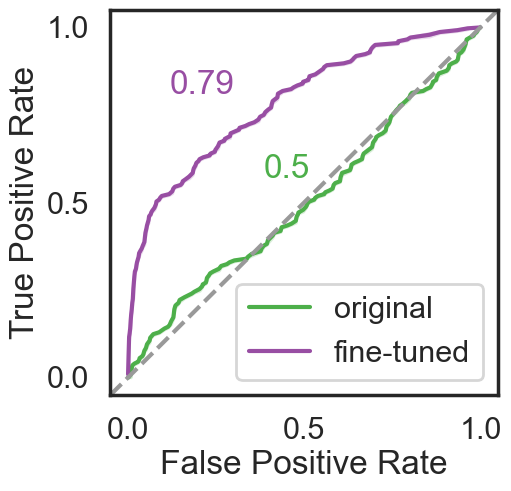

In [21]:
sns.set(rc={'figure.figsize':(5, 5)}, style='white', context='poster')
chart = sns.lineplot(roc_distr, x='fpr', y='tpr', hue='model', hue_order=['original', 'fine-tuned'], palette=[palette[2], palette[3]])
chart.set(xlabel='False Positive Rate', ylabel='True Positive Rate', xticks=np.arange(0, 1.1, 0.5), yticks=np.arange(0, 1.1, 0.5))
# random model
chart.axline((0, 0), slope=1, linestyle='--', color=palette[8])
# original model
roc_auc = roc_distr[(roc_distr['model'] == 'original')]['roc_auc_score'].iloc[0]
chart.text(x=1-roc_auc-0.05, y=roc_auc+0.05, s=f'{roc_auc}', va='bottom', ha='center', color=palette[2])
# chart.text(x=0.5, y=0.5, s=f'{roc_auc}', va='bottom', ha='center', color=palette[2])
# best_epoch
roc_auc = roc_distr[(roc_distr['model'] == 'fine-tuned')]['roc_auc_score'].iloc[0]
chart.text(x=1-roc_auc, y=roc_auc, s=f'{roc_auc}', va='bottom', ha='center', color=palette[3])
plt.legend(title='')
chart.figure.savefig('../figures/main/Figure 5A Finetune affinity module ROC curve.png', dpi=300, bbox_inches='tight')
chart

<Axes: xlabel='FPR', ylabel='TPR'>

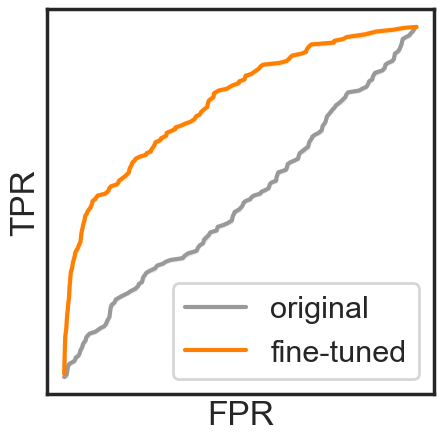

In [37]:
sns.set(rc={'figure.figsize':(5, 5)}, style='white', context='poster')
chart = sns.lineplot(roc_distr, x='fpr', y='tpr', hue='model', hue_order=['original', 'fine-tuned'], palette=[palette[8], palette[4
]])
chart.set(xlabel='FPR', ylabel='TPR', xticks=[], yticks=[])
plt.legend(title='')
chart.figure.savefig('../figures/TOC ROC curve.png', dpi=300, bbox_inches='tight')
chart

### precision-recall curve

In [22]:
precision_recall_distr = []
for model, sub_df in test_predictions.groupby(by='model'):
    Y_true = sub_df['affinity_binary_label'].to_numpy()
    Y_pred = sub_df['affinity_probability_binary2'].to_numpy()
    precision, recall, _ = precision_recall_curve(Y_true, Y_pred)
    score = average_precision_score(Y_true, Y_pred)
    model_precision_recall = {'model': model, 'precision': precision, 'recall': recall, 'ap': round(score, 2)}
    precision_recall_distr.append(pd.DataFrame(model_precision_recall))
precision_recall_distr = pd.concat(precision_recall_distr, ignore_index=True)

<Axes: xlabel='Recall', ylabel='Precision'>

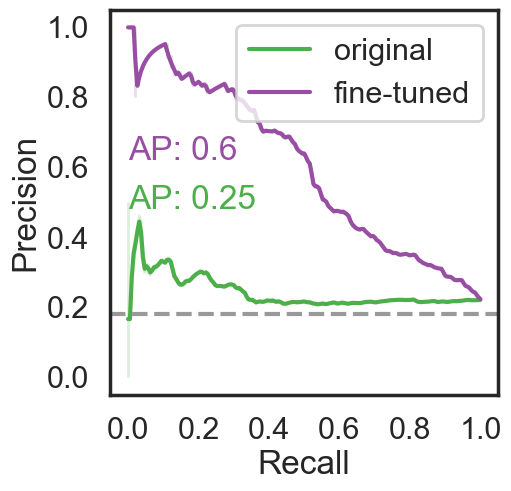

In [31]:
sns.set(rc={'figure.figsize':(5, 5)}, style='white', context='poster')
chart = sns.lineplot(precision_recall_distr, x='recall', y='precision', hue='model', hue_order=['original', 'fine-tuned'], palette=[palette[2], palette[3]])
chart.set(xlabel='Recall', ylabel='Precision', xticks=np.arange(0, 1.2, 0.2), yticks=np.arange(0, 1.2, 0.2))
# random model
chart.axhline(random_model_metrics['precision'], color=palette[8], linestyle='--')
# original model
ap = precision_recall_distr[(precision_recall_distr['model'] == 'original')]['ap'].iloc[0]
chart.text(x=0, y=ap+0.3, s=f'AP: {ap}', va='top', ha='left', color=palette[2])
# best epoch
ap = precision_recall_distr[(precision_recall_distr['model'] == 'fine-tuned')]['ap'].iloc[0]
chart.text(x=0, y=ap, s=f'AP: {ap}', va='bottom', ha='left', color=palette[3])
plt.legend(title='')
chart.figure.savefig('../figures/main/Figure 5B Finetune affinity module precision-recall curve.png', dpi=300, bbox_inches='tight')
chart

### receptor based metrics

In [24]:
rid_metrics_distr = []
for (model, rid), sub_df in test_predictions.groupby(by=['model', 'rid']):
    
    agonist_num = len(sub_df[sub_df['affinity_binary_label'] == 1])
    non_agonist_num = len(sub_df[sub_df['affinity_binary_label'] == 0])

    if agonist_num >= 5 and non_agonist_num >= 5:
        meta = pd.Series({'model': model, 'rid': rid})
        metrics = calculate_metrics(sub_df, classification_threshold=best_t)
        rid_metrics = pd.concat([meta, metrics])
        rid_metrics_distr.append(rid_metrics.to_frame().T)

rid_metrics_distr = pd.concat(rid_metrics_distr, ignore_index=True)

### receptor based auroc

<Axes: xlabel='TAS2R', ylabel='AUROC'>

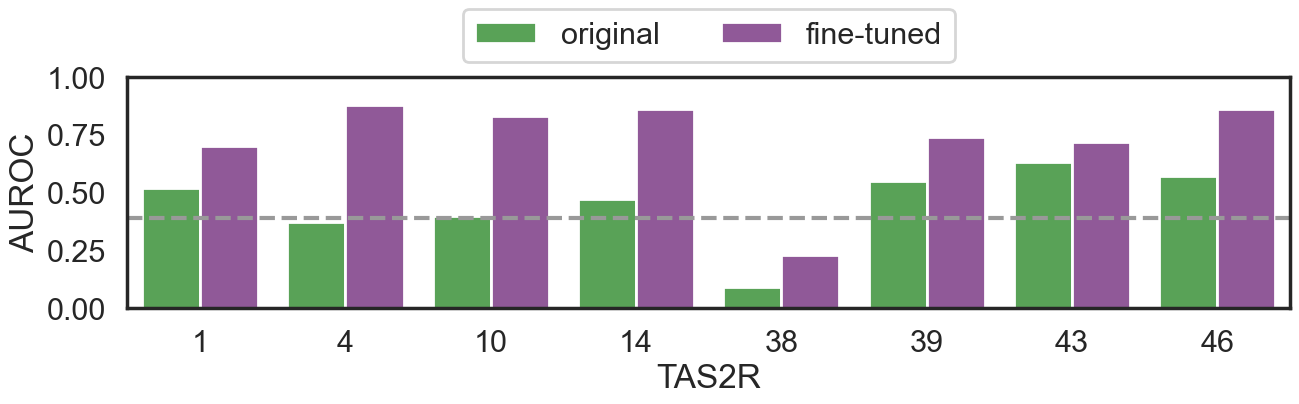

In [25]:
sns.set(rc={'figure.figsize':(15, 3)}, style='white', context='poster')
chart = sns.barplot(rid_metrics_distr, x='rid', y='roc_auc', hue='model', hue_order=['original', 'fine-tuned'], palette=[palette[2], palette[3]])
chart.set(xlabel='TAS2R', ylabel='AUROC', yticks=np.arange(0, 1.25, 0.25))
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 1), ncol=2, title='')
# random model
chart.axhline(random_model_metrics['balanced_accuracy'], color=palette[8], linestyle='--')
chart.figure.savefig('../figures/supplementary/Supplementary Figure 7A Finetune affinity module receptors AUROC.png', dpi=300, bbox_inches='tight')
chart

### receptor average precision

<Axes: xlabel='TAS2R', ylabel='Average precision'>

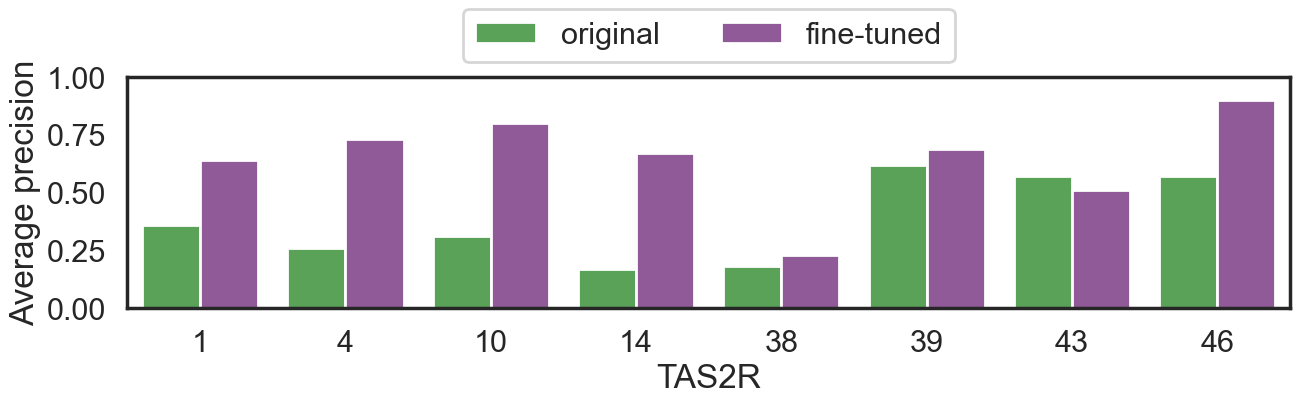

In [26]:
sns.set(rc={'figure.figsize':(15, 3)}, style='white', context='poster')
chart = sns.barplot(rid_metrics_distr, x='rid', y='average_precision', hue='model', hue_order=['original', 'fine-tuned'], palette=[palette[2], palette[3]])
chart.set(xlabel='TAS2R', ylabel='Average precision', yticks=np.arange(0, 1.25, 0.25))
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 1), ncol=2, title='')
chart.figure.savefig('../figures/supplementary/Supplementary Figure 7B Finetune affinity module receptors AP.png', dpi=300, bbox_inches='tight')
chart